# Q1/Q2 Mystery and Heidelberg Astrolabium Comparison

Two open questions about the Voynich zodiac section:

**Part A — Q1/Q2**: Position 1 in zodiac labels takes two main values (Q1, Q2) whose function is unknown. Previous tests (nb70-71) ruled out season, element, modality, fertility, and human/animal type. This notebook tests Q1/Q2 against the **visual features** cataloged in notebook 72 (tubes, dress, crowns, missing stars, center stars).

**Part B — Heidelberg Astrolabium**: The Astrolabium Planum (Cod. Pal. germ. 832, based on Pietro d'Abano, c.1300) is the closest structural parallel to the Voynich zodiac: 360 degree-figures with text and horoscope tables. Both manuscripts encode degree-level astrological properties. This section compares the structure and properties encoded in each.

In [11]:
import json, re
import numpy as np
import pandas as pd
from scipy import stats
from collections import Counter, defaultdict
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_style('whitegrid')
plt.rcParams['figure.dpi'] = 120

# --- Parse zodiac labels (same as nb71) ---
sign_map = {
    'f70v2':'Pisces','f70v1':'Aries','f71r':'Aries','f71v':'Taurus',
    'f72r1':'Taurus','f72r2':'Gemini','f72r3':'Cancer','f72v3':'Leo',
    'f72v2':'Virgo','f72v1':'Libra','f73r':'Scorpio','f73v':'Sagittarius'
}
SIGN_ORDER = ['Pisces','Aries','Taurus','Gemini','Cancer','Leo',
              'Virgo','Libra','Scorpio','Sagittarius']

labels = []
headers = []
dc = defaultdict(int)
with open('corpus/voynich_sta.txt') as f:
    for line in f:
        line = line.strip()
        if not line or line.startswith('#'): continue
        m = re.match(r'<(f\d+[rv]\d*)', line)
        if not m: continue
        folio = m.group(1)
        if folio not in sign_map: continue
        sign = sign_map[folio]
        words = re.findall(r'[A-Z][A-Za-z0-9]*', line[m.end():])
        for w in words:
            atoms = re.findall(r'[A-Z][a-z0-9]*', w)
            n = len(atoms)
            if n < 3: continue
            entry = {'word': w, 'atoms': atoms, 'n': n, 'sign': sign,
                     'folio': folio, 'degree': dc[(sign,)]}
            if n <= 7:
                labels.append(entry)
                dc[(sign,)] += 1
            else:
                headers.append(entry)

# Load visual catalog
with open('zodiac/visual_catalog.json') as f:
    catalog = json.load(f)

# Load Lilly
with open('zodiac/lilly_degree_table.json') as f:
    lilly = json.load(f)

print(f"Labels: {len(labels)}, Headers: {len(headers)}")
print(f"Signs: {len(set(l['sign'] for l in labels))}")

Labels: 1086, Headers: 53
Signs: 10


## Part A: Q1/Q2 Mystery

### A.1 Identify Q1 and Q2 atoms

In [12]:
# Position 1 atom distribution (labels with n >= 4 to have meaningful pos1)
pos1_counts = Counter()
for l in labels:
    if l['n'] >= 4:
        pos1_counts[l['atoms'][1]] += 1

print("=== Pos1 atom distribution (labels with n>=4) ===\n")
for atom, count in pos1_counts.most_common(15):
    pct = count / sum(pos1_counts.values()) * 100
    print(f"  {atom:6s}: {count:3d} ({pct:5.1f}%)")

# Identify Q1 and Q2 as the two most common pos1 atoms
q_atoms = [atom for atom, _ in pos1_counts.most_common(2)]
Q1, Q2 = q_atoms[0], q_atoms[1]
print(f"\nQ1 = {Q1} ({pos1_counts[Q1]} occurrences)")
print(f"Q2 = {Q2} ({pos1_counts[Q2]} occurrences)")
print(f"Other pos1 atoms: {sum(pos1_counts.values()) - pos1_counts[Q1] - pos1_counts[Q2]}")

# Distribution by sign
print("\n=== Q1/Q2 distribution by sign ===\n")
print(f"{'Sign':12s} {'Total':5s} {'Q1':4s} {'Q2':4s} {'Other':5s} {'Q1%':5s} {'Q2%':5s} {'Dominant':10s}")
print("-" * 60)

sign_q_data = {}
for sign in SIGN_ORDER:
    sign_labels = [l for l in labels if l['sign'] == sign and l['n'] >= 4]
    n = len(sign_labels)
    q1_n = sum(1 for l in sign_labels if l['atoms'][1] == Q1)
    q2_n = sum(1 for l in sign_labels if l['atoms'][1] == Q2)
    other_n = n - q1_n - q2_n
    q1_pct = q1_n / n * 100 if n > 0 else 0
    q2_pct = q2_n / n * 100 if n > 0 else 0
    dominant = 'Q1' if q1_pct > q2_pct + 10 else ('Q2' if q2_pct > q1_pct + 10 else 'balanced')
    sign_q_data[sign] = {'q1': q1_n, 'q2': q2_n, 'other': other_n, 'total': n,
                         'q1_pct': q1_pct, 'q2_pct': q2_pct, 'dominant': dominant}
    print(f"  {sign:12s} {n:5d} {q1_n:4d} {q2_n:4d} {other_n:5d} {q1_pct:5.1f} {q2_pct:5.1f} {dominant:10s}")

=== Pos1 atom distribution (labels with n>=4) ===

  Q2    : 287 ( 31.6%)
  Q1    : 198 ( 21.8%)
  J1    : 113 ( 12.4%)
  A1    :  79 (  8.7%)
  B2    :  54 (  5.9%)
  P1    :  31 (  3.4%)
  A3    :  30 (  3.3%)
  K2    :  26 (  2.9%)
  C1    :  22 (  2.4%)
  K1    :  12 (  1.3%)
  P2    :  11 (  1.2%)
  B1    :   7 (  0.8%)
  Qa    :   6 (  0.7%)
  C2    :   5 (  0.6%)
  F3    :   5 (  0.6%)

Q1 = Q2 (287 occurrences)
Q2 = Q1 (198 occurrences)
Other pos1 atoms: 424

=== Q1/Q2 distribution by sign ===

Sign         Total Q1   Q2   Other Q1%   Q2%   Dominant  
------------------------------------------------------------
  Pisces          89   42   15    32  47.2  16.9 Q1        
  Aries          111   48   26    37  43.2  23.4 Q1        
  Taurus         129   46   26    57  35.7  20.2 Q1        
  Gemini          72   23   26    23  31.9  36.1 balanced  
  Cancer         119   26   20    73  21.8  16.8 balanced  
  Leo             87   20   27    40  23.0  31.0 balanced  
  Virgo      

### A.2 Q1/Q2 dominance vs visual features

Test whether Q1/Q2 dominance per sign correlates with the visual features from notebook 72.

=== Combined Q1/Q2 + Visual Features ===

       sign season  q1_pct  q2_pct dominant  has_tubes  has_dressed  missing_stars  crowns  center_stars
     Pisces Winter    47.2    16.9       Q1       True        False              0       0             2
      Aries Spring    43.2    23.4       Q1       True         True              0       0             0
     Taurus Spring    35.7    20.2       Q1       True         True              0       0             0
     Gemini Spring    31.9    36.1 balanced       True        False              0       0             0
     Cancer Summer    21.8    16.8 balanced      False        False              2       1             0
        Leo Summer    23.0    31.0 balanced      False        False              1       0             0
      Virgo Summer    22.4    22.4 balanced      False        False              1       0             1
      Libra Autumn    33.8    16.2       Q1      False        False              0       1             0
    Scorpio A

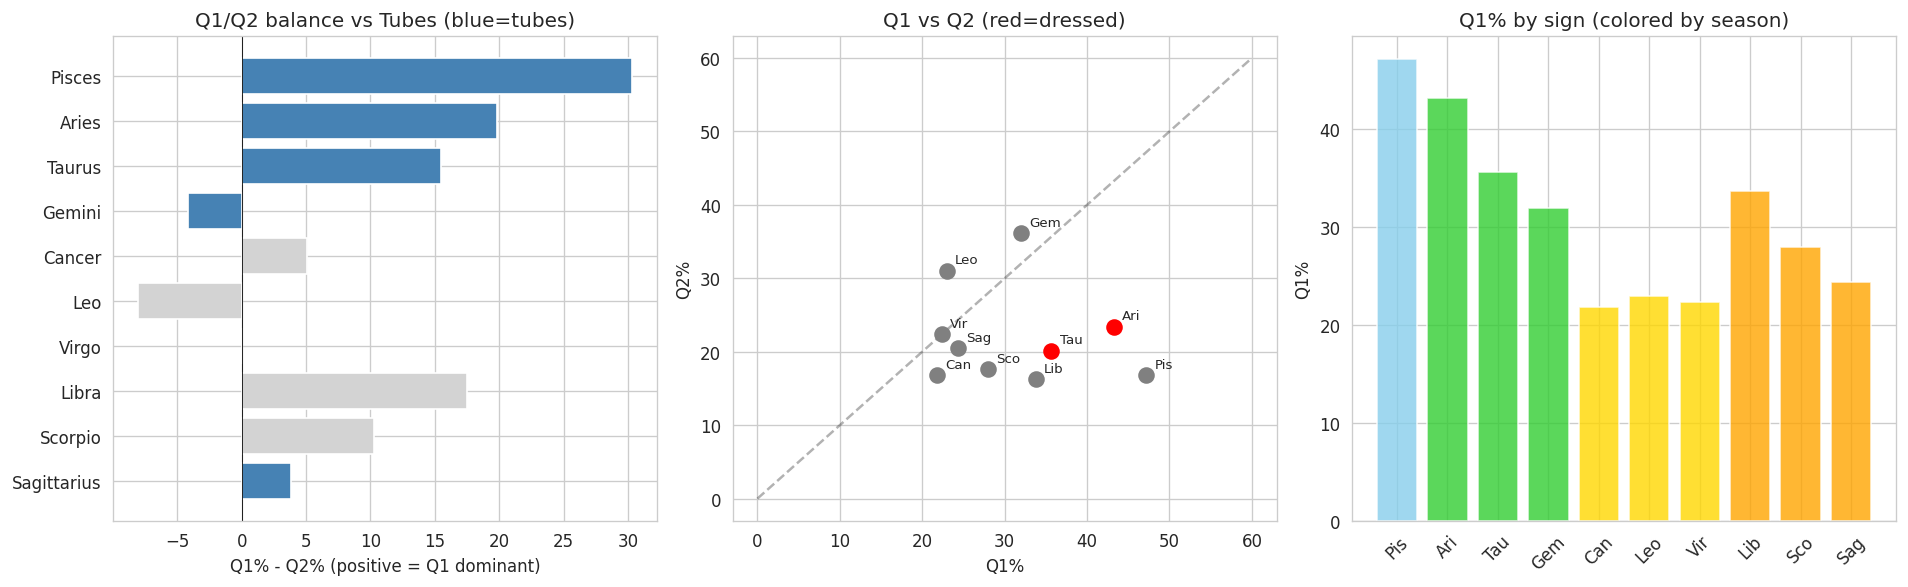

In [13]:
# Build combined table: Q1/Q2 + visual features
SEASONS = {'Pisces':'Winter','Aries':'Spring','Taurus':'Spring','Gemini':'Spring',
           'Cancer':'Summer','Leo':'Summer','Virgo':'Summer',
           'Libra':'Autumn','Scorpio':'Autumn','Sagittarius':'Autumn'}

rows = []
for sign in SIGN_ORDER:
    c = catalog[sign]
    qd = sign_q_data[sign]
    
    # Tubes
    tube_types = set()
    for ring in c['rings']:
        if ring['tubes'] != 'none':
            tube_types.add(ring['tubes'])
    if c.get('outside') and 'tube' in str(c['outside'].get('notes','')).lower():
        tube_types.add('horizontal')
    has_tubes = len(tube_types) > 0
    
    # Dress
    has_dressed = any('dressed' in r['dress'] or 'transparent' in r['dress'] for r in c['rings'])
    
    # Missing stars
    missing = sum(r['n_nymphs'] - r['stars'] for r in c['rings'])
    
    # Crowns
    crowns = sum(r['crowns'] for r in c['rings'])
    
    # Outside nymphs
    outside = c['outside']['n'] if c.get('outside') else 0
    
    # Number of rings
    n_rings = len(c['rings'])
    
    # Pages
    pages = c['pages']
    
    rows.append({
        'sign': sign, 'season': SEASONS[sign],
        'q1_pct': qd['q1_pct'], 'q2_pct': qd['q2_pct'],
        'q1_minus_q2': qd['q1_pct'] - qd['q2_pct'],
        'dominant': qd['dominant'],
        'has_tubes': has_tubes, 'has_dressed': has_dressed,
        'missing_stars': missing, 'crowns': crowns,
        'center_stars': c['center_stars'], 'outside': outside,
        'n_rings': n_rings, 'pages': pages
    })

df = pd.DataFrame(rows)

# Display
print("=== Combined Q1/Q2 + Visual Features ===\n")
cols = ['sign','season','q1_pct','q2_pct','dominant','has_tubes','has_dressed','missing_stars','crowns','center_stars']
print(df[cols].to_string(index=False, float_format='%.1f'))

# Visual: Q1% vs Q2% colored by visual features
fig, axes = plt.subplots(1, 3, figsize=(16, 5))

# 1. Q1-Q2 balance by sign, colored by tubes
ax = axes[0]
colors = ['steelblue' if t else 'lightgray' for t in df.has_tubes]
ax.barh(range(len(SIGN_ORDER)), df.q1_minus_q2, color=colors)
ax.set_yticks(range(len(SIGN_ORDER)))
ax.set_yticklabels(SIGN_ORDER)
ax.axvline(0, color='black', linewidth=0.5)
ax.set_xlabel('Q1% - Q2% (positive = Q1 dominant)')
ax.set_title('Q1/Q2 balance vs Tubes (blue=tubes)')
ax.invert_yaxis()

# 2. Q1% vs Q2% scatter, colored by dress
ax = axes[1]
for _, r in df.iterrows():
    c_color = 'red' if r.has_dressed else 'gray'
    ax.scatter(r.q1_pct, r.q2_pct, c=c_color, s=80, zorder=5)
    ax.annotate(r.sign[:3], (r.q1_pct+1, r.q2_pct+1), fontsize=8)
ax.plot([0,60],[0,60], 'k--', alpha=0.3)
ax.set_xlabel('Q1%'); ax.set_ylabel('Q2%')
ax.set_title('Q1 vs Q2 (red=dressed)')

# 3. Q1% by season
ax = axes[2]
season_colors = {'Winter':'skyblue','Spring':'limegreen','Summer':'gold','Autumn':'orange'}
for _, r in df.iterrows():
    ax.bar(r.sign[:3], r.q1_pct, color=season_colors[r.season], alpha=0.8)
ax.set_ylabel('Q1%')
ax.set_title('Q1% by sign (colored by season)')
ax.tick_params(axis='x', rotation=45)

plt.tight_layout()
plt.savefig('images/zodiac_q1q2_visual.png', dpi=150, bbox_inches='tight')
plt.show()

### A.3 Statistical tests: Q1/Q2 vs visual features and untested properties

In [14]:
# Test Q1/Q2 dominance against sign-level properties
# Since Q1/Q2 varies by SIGN (not by degree), we test at the sign level

# Properties to test
sign_properties = {}
for sign in SIGN_ORDER:
    c = catalog[sign]
    tube_types = set()
    for ring in c['rings']:
        if ring['tubes'] != 'none': tube_types.add(ring['tubes'])
    if c.get('outside') and 'tube' in str(c['outside'].get('notes','')).lower():
        tube_types.add('horizontal')
    
    sign_properties[sign] = {
        'tubes': len(tube_types) > 0,
        'dressed': any('dressed' in r['dress'] or 'transparent' in r['dress'] for r in c['rings']),
        'crowns': sum(r['crowns'] for r in c['rings']) > 0,
        'center_stars': c['center_stars'] > 0,
        'outside': (c['outside']['n'] if c.get('outside') else 0) > 0,
        'multi_page': c['pages'] > 1,
        'three_rings': len(c['rings']) >= 3,
        # Astrological (not tested at sign level before)
        'diurnal': sign in ['Aries','Taurus','Gemini','Cancer','Leo','Virgo'],  # above horizon
        'northern': sign in ['Aries','Taurus','Gemini','Cancer','Leo','Virgo'],
        'bestial': sign in ['Aries','Taurus','Leo','Sagittarius','Capricorn'],  # bestial signs
        'feral': sign in ['Leo'],  # feral/wild
        'mute': sign in ['Cancer','Scorpio','Pisces'],  # mute signs
        'voice': sign in ['Gemini','Virgo','Libra','Sagittarius'],  # voice signs (human)
        'bicorporeal': sign in ['Gemini','Sagittarius','Pisces'],  # double-bodied
        'commanding': sign in ['Aries','Taurus','Gemini','Cancer','Leo','Virgo'],  # commanding signs
        'obeying': sign in ['Libra','Scorpio','Sagittarius','Capricorn','Aquarius','Pisces'],
    }

# For each property, test Fisher exact: Q1-dominant vs Q2-dominant × property yes/no
print("=== Fisher exact tests: Q1/Q2 dominance × sign properties ===\n")
print(f"{'Property':18s} {'Q1-dom & Yes':12s} {'Q1-dom & No':12s} {'Q2-dom & Yes':12s} {'Q2-dom & No':12s} {'OR':8s} {'p':8s}")
print("-" * 80)

test_results = []
for prop_name in sorted(sign_properties['Pisces'].keys()):
    # Classify signs by Q1/Q2 dominance
    table = [[0,0],[0,0]]  # [Q2-dom/balanced, Q1-dom] × [No, Yes]
    for sign in SIGN_ORDER:
        qd = sign_q_data[sign]
        is_q1_dom = qd['q1_pct'] > qd['q2_pct']
        has_prop = sign_properties[sign][prop_name]
        i = 1 if is_q1_dom else 0
        j = 1 if has_prop else 0
        table[i][j] += 1
    
    odds, p = stats.fisher_exact(table)
    sig = '*' if p < 0.05 else ''
    test_results.append({'property': prop_name, 'table': table, 'OR': odds, 'p': p})
    print(f"  {prop_name:18s} {table[1][1]:12d} {table[1][0]:12d} {table[0][1]:12d} {table[0][0]:12d} {odds:8.2f} {p:8.4f} {sig}")

# Sort by p-value
print("\n=== Ranked by p-value ===\n")
for r in sorted(test_results, key=lambda x: x['p'])[:5]:
    print(f"  {r['property']:18s} p={r['p']:.4f} OR={r['OR']:.2f}")

# Bonferroni correction
n_tests = len(test_results)
bonf = 0.05 / n_tests
sig_bonf = [r for r in test_results if r['p'] < bonf]
print(f"\nBonferroni threshold: {bonf:.4f} ({n_tests} tests)")
print(f"Significant after Bonferroni: {len(sig_bonf)}")

=== Fisher exact tests: Q1/Q2 dominance × sign properties ===

Property           Q1-dom & Yes Q1-dom & No  Q2-dom & Yes Q2-dom & No  OR       p       
--------------------------------------------------------------------------------
  bestial                       3            4            1            2     1.50   1.0000 
  bicorporeal                   2            5            1            2     0.80   1.0000 
  center_stars                  2            5            1            2     0.80   1.0000 
  commanding                    3            4            3            0     0.00   0.2000 
  crowns                        3            4            0            3      inf   0.4750 
  diurnal                       3            4            3            0     0.00   0.2000 
  dressed                       2            5            0            3      inf   1.0000 
  feral                         0            7            1            2     0.00   0.3000 
  multi_page                   

### A.4 Q1/Q2 at the degree level: Lilly's degree properties

Q1/Q2 might encode a degree-level property rather than a sign-level one. Test against Lilly's masculine/feminine alternation, deep/pitted, azimene, and increasing fortune.

In [15]:
# Assign degree properties from Lilly to each label
# Masculine/feminine is encoded as alternating ranges with upper bounds
def get_masc_fem(sign, degree):
    """Return 'M' or 'F' based on Lilly's alternating ranges."""
    s = lilly['signs'][sign]
    # Build ranges from upper bounds
    bounds_m = sorted(s['masculine'])
    bounds_f = sorted(s['feminine'])
    # Merge and sort all bounds with their type
    all_bounds = [(b, 'M') for b in bounds_m] + [(b, 'F') for b in bounds_f]
    all_bounds.sort(key=lambda x: x[0])
    # Degree falls in the range whose upper bound >= degree
    for bound, mf in all_bounds:
        if degree <= bound:
            return mf
    return 'M'  # default if beyond last bound

# Assign properties to each label
for l in labels:
    if l['n'] < 4: continue
    sign = l['sign']
    # Degree = position in sign (1-indexed)
    deg = l['degree'] + 1  # dc starts at 0
    if deg > 30: deg = 30
    
    s = lilly['signs'][sign]
    l['masc_fem'] = get_masc_fem(sign, deg)
    l['pitted'] = deg in s['deep_pitted']
    l['azimene'] = deg in s['azimene']
    l['fortune'] = deg in s['increasing_fortune']
    l['degree_1idx'] = deg

# Test Q1/Q2 × each Lilly property
print("=== Q1/Q2 (pos1 atom) × Lilly degree properties ===\n")

lilly_props = ['masc_fem', 'pitted', 'azimene', 'fortune']
subset = [l for l in labels if l['n'] >= 4 and l['atoms'][1] in [Q1, Q2]]

for prop in lilly_props:
    ct = defaultdict(Counter)
    for l in subset:
        q = 'Q1' if l['atoms'][1] == Q1 else 'Q2'
        val = l[prop]
        ct[q][val] += 1
    
    print(f"  {prop}:")
    vals = sorted(set(v for c in ct.values() for v in c))
    for q in ['Q1', 'Q2']:
        counts = [ct[q].get(v, 0) for v in vals]
        print(f"    {q}: {dict(zip(vals, counts))}")
    
    # Build contingency table
    table = []
    for q in ['Q1', 'Q2']:
        table.append([ct[q].get(v, 0) for v in vals])
    table = np.array(table)
    
    if table.shape[1] >= 2 and table.min() >= 0:
        if table.shape == (2, 2):
            odds, p = stats.fisher_exact(table)
            print(f"    Fisher exact: OR={odds:.2f}, p={p:.4f}")
        else:
            chi2, p, dof, _ = stats.chi2_contingency(table)
            print(f"    Chi2={chi2:.2f}, p={p:.4f}, dof={dof}")
    print()

# Also test: Q1/Q2 × decanate (degrees 1-10, 11-20, 21-30)
print("=== Q1/Q2 × Decanate (face) ===\n")
ct_dec = defaultdict(Counter)
for l in subset:
    q = 'Q1' if l['atoms'][1] == Q1 else 'Q2'
    deg = l['degree_1idx']
    decanate = 1 if deg <= 10 else (2 if deg <= 20 else 3)
    ct_dec[q][decanate] += 1

for q in ['Q1', 'Q2']:
    print(f"  {q}: dec1={ct_dec[q][1]}, dec2={ct_dec[q][2]}, dec3={ct_dec[q][3]}")

table_dec = np.array([[ct_dec['Q1'][d] for d in [1,2,3]],
                       [ct_dec['Q2'][d] for d in [1,2,3]]])
chi2, p, dof, _ = stats.chi2_contingency(table_dec)
print(f"  Chi2={chi2:.2f}, p={p:.4f}, dof={dof}")

# Q1/Q2 × ring position (inner vs outer)
print("\n=== Q1/Q2 × Ring position ===")
print("  (Approximate: first N nymphs = inner ring, rest = outer)")
ct_ring = defaultdict(Counter)
for l in subset:
    q = 'Q1' if l['atoms'][1] == Q1 else 'Q2'
    sign = l['sign']
    deg = l['degree_1idx']
    inner_n = catalog[sign]['rings'][0]['n_nymphs']
    ring = 'inner' if deg <= inner_n else 'outer'
    ct_ring[q][ring] += 1

for q in ['Q1', 'Q2']:
    print(f"  {q}: inner={ct_ring[q]['inner']}, outer={ct_ring[q]['outer']}")
table_ring = np.array([[ct_ring['Q1']['inner'], ct_ring['Q1']['outer']],
                        [ct_ring['Q2']['inner'], ct_ring['Q2']['outer']]])
odds_r, p_r = stats.fisher_exact(table_ring)
print(f"  Fisher: OR={odds_r:.2f}, p={p_r:.4f}")

=== Q1/Q2 (pos1 atom) × Lilly degree properties ===

  masc_fem:
    Q1: {'F': 51, 'M': 236}
    Q2: {'F': 39, 'M': 159}
    Fisher exact: OR=0.88, p=0.6351

  pitted:
    Q1: {False: 208, True: 79}
    Q2: {False: 138, True: 60}
    Fisher exact: OR=1.14, p=0.5404

  azimene:
    Q1: {False: 280, True: 7}
    Q2: {False: 194, True: 4}
    Fisher exact: OR=0.82, p=1.0000

  fortune:
    Q1: {False: 276, True: 11}
    Q2: {False: 193, True: 5}
    Fisher exact: OR=0.65, p=0.6063

=== Q1/Q2 × Decanate (face) ===

  Q1: dec1=32, dec2=17, dec3=238
  Q2: dec1=16, dec2=18, dec3=164
  Chi2=2.74, p=0.2536, dof=2

=== Q1/Q2 × Ring position ===
  (Approximate: first N nymphs = inner ring, rest = outer)
  Q1: inner=26, outer=261
  Q2: inner=17, outer=181
  Fisher: OR=1.06, p=1.0000


## Part B: Heidelberg Astrolabium Planum Comparison

The Heidelberg Cod. Pal. germ. 832 contains 360 degree illustrations (4 per page, starting at Aries p.80). Each degree has:
1. An **illustration** (person/animal/scene)
2. A **description** in German ("Ein man mit..." = nativity description)
3. A **prediction** in red ("Wird ein..." = character prediction)
4. A **horoscope table** (planetary positions in houses for that degree)

### B.1 Structural comparison

In [16]:
# Heidelberg Astrolabium Planum structure
# Based on visual inspection of downloaded pages (zodiac/images/heidelberg_astrolabium/)

heidelberg = {
    'manuscript': 'Cod. Pal. germ. 832, Universitatsbibliothek Heidelberg',
    'date': 'post-1491 (based on d\'Abano system, c.1300)',
    'pages_total': 200,
    'structure': {
        'calendar': {'pages': '8-16', 'content': 'Monthly calendars with saints\' days, sunrise/sunset times'},
        'tables': {'pages': '37', 'content': 'Bloodletting table (Tafel der Aderlassung) by sign and degree: Gut/Mittel/Bos'},
        'text': {'pages': '38-39', 'content': 'Instructions on bloodletting and astrological medicine'},
        'cosmology': {'pages': '40-41', 'content': 'Cosmological diagram (concentric circles with zodiac, planets, elements)'},
        'eclipses': {'pages': '42-43', 'content': 'Eclipse tables and illustrations (1491-1502)'},
        'astrolabe_text': {'pages': '70-75', 'content': 'Instructions for using the astrolabium planum'},
        'degree_figures': {'pages': '80-175 (approx)', 'content': '360 degree illustrations, 4 per page'},
        'sign_descriptions': {'pages': '176-200', 'content': 'Sign descriptions with zodiac animal illustrations'},
    },
    'degree_figure_structure': {
        'per_page': 4,
        'per_sign': 30,
        'pages_per_sign': 8,  # 30/4 = 7.5, rounded up
        'total': 360,
        'components': [
            'Illustration (miniature painting)',
            'Nativity description (German, black ink)',
            'Character prediction (German, red ink, "Wird ein...")',
            'Horoscope table (planetary positions in 12 houses)',
        ]
    },
    'sign_order_degrees': 'Zodiacal (Aries first)',  # NOT calendar
    'sign_order_calendar': 'Calendar (January/Aquarius first)',
    'degree_pages': {
        'Aries': 80, 'Taurus': 88, 'Gemini': 96, 'Cancer': 104,
        'Leo': 112, 'Virgo': 120, 'Libra': 128, 'Scorpio': 136,
        'Sagittarius': 144, 'Capricorn': 152, 'Aquarius': 160, 'Pisces': 168
    }
}

# Voynich zodiac structure for comparison
voynich = {
    'manuscript': 'Beinecke MS 408, ff. 70v2-73v',
    'date': 'c. 1404-1438 (radiocarbon)',
    'pages_total': '~10 folios (20 pages)',
    'degree_figure_structure': {
        'per_page': '10-20 (concentric rings)',
        'per_sign': 30,
        'total': '299 surviving (360 predicted)',
        'components': [
            'Nymph figure (naked/dressed, with/without star)',
            'Text label (4-7 atoms in Voynichese)',
            'Visual features (tubes, crowns, dress)',
        ]
    },
    'sign_order': 'Calendar (Pisces/February first)',
    'missing_signs': ['Capricorn', 'Aquarius'],
    'layout': 'Concentric rings on circular diagrams'
}

# Side-by-side comparison
print("=" * 80)
print("STRUCTURAL COMPARISON: Voynich Zodiac vs Heidelberg Astrolabium Planum")
print("=" * 80)

comparison = [
    ('Date', 'c. 1404-1438', 'post-1491 (system c.1300)'),
    ('Entries per sign', '30 nymphs', '30 degree figures'),
    ('Total entries', '299 (10 signs)', '360 (12 signs)'),
    ('Order (degrees)', 'Calendar (Pisces=Feb)', 'Zodiacal (Aries=Mar)'),
    ('Order (calendar)', 'Calendar (Pisces=Feb)', 'Calendar (Aquarius=Jan)'),
    ('Layout', 'Concentric rings', 'Grid (4/page)'),
    ('Figure type', 'Nymph with star', 'Person/animal scene'),
    ('Text per degree', '1 word (4-7 atoms)', '2-3 sentences'),
    ('Horoscope data', 'None visible', 'Full 12-house table'),
    ('Decanate markers', '3 illustrations at top', '3 illustrations at top'),
    ('Language', 'Voynichese (encoded)', 'German (readable)'),
    ('Medical content', 'Unknown', 'Bloodletting table (p.37)'),
    ('Properties encoded', 'Season, fertility, sign type', 'Nativity, character, houses'),
    ('Encoding method', 'Positional atoms', 'Natural language'),
]

print(f"\n{'Feature':22s} {'Voynich':30s} {'Heidelberg':30s}")
print("-" * 85)
for feat, v, h in comparison:
    print(f"  {feat:22s} {v:30s} {h:30s}")

STRUCTURAL COMPARISON: Voynich Zodiac vs Heidelberg Astrolabium Planum

Feature                Voynich                        Heidelberg                    
-------------------------------------------------------------------------------------
  Date                   c. 1404-1438                   post-1491 (system c.1300)     
  Entries per sign       30 nymphs                      30 degree figures             
  Total entries          299 (10 signs)                 360 (12 signs)                
  Order (degrees)        Calendar (Pisces=Feb)          Zodiacal (Aries=Mar)          
  Order (calendar)       Calendar (Pisces=Feb)          Calendar (Aquarius=Jan)       
  Layout                 Concentric rings               Grid (4/page)                 
  Figure type            Nymph with star                Person/animal scene           
  Text per degree        1 word (4-7 atoms)             2-3 sentences                 
  Horoscope data         None visible                   Full 

### B.2 Decanate structure: 3 faces per sign

Both manuscripts mark the three decanates (faces) of each sign. In the Heidelberg, the first page of each sign shows 3 illustrations at the top representing the 3 decanates (degrees 1-10, 11-20, 21-30), each ruled by a different planet. Let's check if the Voynich labels show decanate-level variation.

In [17]:
# Decanate (face) rulers in the Chaldean order system used by d'Abano
# Each decanate is ruled by a planet in Chaldean order: Saturn, Jupiter, Mars, Sun, Venus, Mercury, Moon
CHALDEAN = ['Saturn', 'Jupiter', 'Mars', 'Sun', 'Venus', 'Mercury', 'Moon']

# Aries face 1 = Mars, face 2 = Sun, face 3 = Venus (continuing Chaldean cycle)
decanate_rulers = {}
planet_idx = 0  # Start with Mars for Aries face 1
for sign_idx, sign in enumerate(['Aries','Taurus','Gemini','Cancer','Leo','Virgo',
                                  'Libra','Scorpio','Sagittarius','Capricorn','Aquarius','Pisces']):
    rulers = []
    for face in range(3):
        rulers.append(CHALDEAN[planet_idx % 7])
        planet_idx += 1
    decanate_rulers[sign] = rulers

print("=== Decanate rulers (Chaldean order, d'Abano system) ===\n")
print(f"{'Sign':12s} {'Face 1 (1-10)':15s} {'Face 2 (11-20)':15s} {'Face 3 (21-30)':15s}")
print("-" * 60)
for sign in SIGN_ORDER:
    r = decanate_rulers[sign]
    print(f"  {sign:12s} {r[0]:15s} {r[1]:15s} {r[2]:15s}")

# Test: do Voynich labels vary by decanate?
# For each position (1-4), check if atom distribution differs across decanates
print("\n=== Voynich label atoms by decanate (chi2 test) ===\n")
valid_labels = [l for l in labels if l['n'] >= 4 and 'degree_1idx' in l]
for l in valid_labels:
    l['decanate'] = 1 if l['degree_1idx'] <= 10 else (2 if l['degree_1idx'] <= 20 else 3)

for pos in range(1, 5):
    ct = defaultdict(Counter)
    for l in valid_labels:
        if pos < l['n']:
            ct[l['decanate']][l['atoms'][pos]] += 1
    
    # Build contingency table
    all_atoms = sorted(set(a for c in ct.values() for a in c))
    table = np.zeros((3, len(all_atoms)))
    for d in [1, 2, 3]:
        for j, a in enumerate(all_atoms):
            table[d-1, j] = ct[d].get(a, 0)
    
    # Remove rare columns
    mask = table.sum(0) >= 3
    if mask.sum() >= 2:
        chi2, p, dof, _ = stats.chi2_contingency(table[:, mask])
        sig = '***' if p < 0.001 else ('**' if p < 0.01 else ('*' if p < 0.05 else ''))
        print(f"  Pos {pos}: chi2={chi2:.1f}, p={p:.4f}, dof={dof} {sig}")
    else:
        print(f"  Pos {pos}: insufficient data")

print("\nNote: the Heidelberg explicitly marks decanate boundaries with")
print("3 ruler illustrations at the top of each sign's first page.")
print("If Voynich labels encode decanate, we'd expect pos1 or pos2 to show signal.")

=== Decanate rulers (Chaldean order, d'Abano system) ===

Sign         Face 1 (1-10)   Face 2 (11-20)  Face 3 (21-30) 
------------------------------------------------------------
  Pisces       Mercury         Moon            Saturn         
  Aries        Saturn          Jupiter         Mars           
  Taurus       Sun             Venus           Mercury        
  Gemini       Moon            Saturn          Jupiter        
  Cancer       Mars            Sun             Venus          
  Leo          Mercury         Moon            Saturn         
  Virgo        Jupiter         Mars            Sun            
  Libra        Venus           Mercury         Moon           
  Scorpio      Saturn          Jupiter         Mars           
  Sagittarius  Sun             Venus           Mercury        

=== Voynich label atoms by decanate (chi2 test) ===

  Pos 1: chi2=41.8, p=0.1144, dof=32 
  Pos 2: chi2=74.1, p=0.0002, dof=36 ***
  Pos 3: chi2=48.1, p=0.2409, dof=42 
  Pos 4: chi2=28.6,

### B.3 Heidelberg degree properties: what does d'Abano encode?

The Heidelberg degree figures encode per degree:
1. **Image**: a figure/scene (person with object, animal, landscape)
2. **Nativity prediction**: "Ein man/frau..." — physical description and character
3. **Personality**: "Wird ein..." — what kind of person will be born

These are from the **Astrolabium Planum** tradition of Pietro d'Abano (Padua, c.1300), NOT from Lilly (1647). D'Abano's degree properties differ from Lilly's — they focus on **nativity/personality** rather than luminosity/pitted/fortune.

In [18]:
# D'Abano's system vs Lilly's system: what each encodes per degree
print("=" * 80)
print("DEGREE PROPERTY SYSTEMS: d'Abano (Heidelberg) vs Lilly (1647)")
print("=" * 80)

dabano_properties = [
    ('Ascending image', 'A specific figure (man/woman/animal with attributes)',
     'Unique per degree (360 different images)'),
    ('Nativity description', 'Physical appearance and disposition of person born',
     'e.g. "Ein man hat ein sichel in haut und einem krugt"'),
    ('Character prediction', 'Personality and fate of person born',
     'e.g. "Wird ein hoffenig mensch" (Will be a hopeful person)'),
    ('Planetary houses', 'Full horoscope: 7 planets in 12 houses',
     'Numerical table surrounding each figure'),
    ('Decanate ruler', 'Planet ruling the face (1-10, 11-20, 21-30)',
     'Marked by 3 illustrations at sign header'),
]

lilly_properties = [
    ('Masculine/Feminine', 'Alternating gender ranges per sign',
     'e.g. Aries: M.1-8, F.9-22, M.23-30'),
    ('Light/Dark/Smoky/Void', 'Luminosity classification per degree range',
     'e.g. Aries: D.3, L.8, D.16, L.20, V.24...'),
    ('Deep/Pitted', 'Specific degrees considered unlucky for surgery',
     'e.g. Aries: [6, 11, 16, 23, 29]'),
    ('Azimene (lame)', 'Specific degrees causing physical defects',
     'e.g. Taurus: [6, 7, 8, 9, 10]'),
    ('Increasing Fortune', 'Specific degrees of good luck',
     'e.g. Aries: [19]'),
]

print("\nD'ABANO / HEIDELBERG properties:")
for name, desc, example in dabano_properties:
    print(f"  {name:25s}: {desc}")
    print(f"  {'':25s}  Example: {example}")

print("\nLILLY (1647) properties:")
for name, desc, example in lilly_properties:
    print(f"  {name:25s}: {desc}")
    print(f"  {'':25s}  Example: {example}")

print("\n" + "=" * 80)
print("KEY DIFFERENCE:")
print("  D'Abano: UNIQUE content per degree (360 different descriptions)")
print("  Lilly: CATEGORICAL properties shared across degrees")
print()
print("  The Voynich encoding (nb71) found CATEGORICAL correlations")
print("  (season, fertility, sign type) — these match Lilly's system,")
print("  not d'Abano's. But d'Abano's system ALSO includes categorical")
print("  information through the decanate rulers and horoscope tables.")
print()
print("  Hypothesis: the Voynich may encode a SIMPLIFIED version of")
print("  d'Abano's degree properties, retaining only the categorical")
print("  aspects (season, fertility, decanate) while omitting the")
print("  unique nativity descriptions.")

DEGREE PROPERTY SYSTEMS: d'Abano (Heidelberg) vs Lilly (1647)

D'ABANO / HEIDELBERG properties:
  Ascending image          : A specific figure (man/woman/animal with attributes)
                             Example: Unique per degree (360 different images)
  Nativity description     : Physical appearance and disposition of person born
                             Example: e.g. "Ein man hat ein sichel in haut und einem krugt"
  Character prediction     : Personality and fate of person born
                             Example: e.g. "Wird ein hoffenig mensch" (Will be a hopeful person)
  Planetary houses         : Full horoscope: 7 planets in 12 houses
                             Example: Numerical table surrounding each figure
  Decanate ruler           : Planet ruling the face (1-10, 11-20, 21-30)
                             Example: Marked by 3 illustrations at sign header

LILLY (1647) properties:
  Masculine/Feminine       : Alternating gender ranges per sign
                     

### B.4 Calendar order: both start with the year

The Voynich starts at Pisces (February), the Heidelberg calendar starts at Aquarius (January). Both use calendar order rather than the standard astrological order starting at Aries (the vernal equinox). This is a rare convention shared with the Palazzo della Ragione frescoes in Padua.

In [19]:
# Calendar order comparison
print("=== Calendar order in astrological manuscripts ===\n")

order_systems = [
    ('Standard zodiacal', 'Aries (vernal equinox)', 'Most astrological texts'),
    ('Roman calendar', 'Aquarius (January)', 'Heidelberg calendar (pp.8-16)'),
    ('', 'Aries (March)', 'Heidelberg degrees (pp.80+)'),
    ('Voynich zodiac', 'Pisces (February)', 'ff. 70v2-73v'),
    ('Palazzo della Ragione', 'Aquarius (January)', 'Padua frescoes, 1420 repaint'),
    ('BnF hebr. 1199', 'Aquarius (January)', 'Jewish astrological MS, Italy'),
]

print(f"{'Manuscript':25s} {'First sign':20s} {'Context':35s}")
print("-" * 85)
for ms, first, ctx in order_systems:
    print(f"  {ms:25s} {first:20s} {ctx:35s}")

print("\nKey observation:")
print("  The Heidelberg has TWO orderings:")
print("    - Calendar section (pp.8-16): Aquarius/January first")
print("    - Degree figures (pp.80+): Aries first (standard zodiacal)")
print()
print("  The Voynich uses calendar order for everything.")
print("  Starting at Pisces (Feb) rather than Aquarius (Jan) may indicate:")
print("    1. A different calendar tradition (Byzantine? Jewish?)")
print("    2. Loss of the Aquarius section (f70 foldout hypothesis)")
print("    3. February as the 'true' start of the astronomical year")
print()
print("  In the Jewish calendar, the month of Adar (Feb-Mar) falls in Pisces.")
print("  Shevat (Jan-Feb) falls in Aquarius. If the author followed a")
print("  Jewish reckoning where the year starts with Adar/Purim season,")
print("  Pisces-first would be natural.")

=== Calendar order in astrological manuscripts ===

Manuscript                First sign           Context                            
-------------------------------------------------------------------------------------
  Standard zodiacal         Aries (vernal equinox) Most astrological texts            
  Roman calendar            Aquarius (January)   Heidelberg calendar (pp.8-16)      
                            Aries (March)        Heidelberg degrees (pp.80+)        
  Voynich zodiac            Pisces (February)    ff. 70v2-73v                       
  Palazzo della Ragione     Aquarius (January)   Padua frescoes, 1420 repaint       
  BnF hebr. 1199            Aquarius (January)   Jewish astrological MS, Italy      

Key observation:
  The Heidelberg has TWO orderings:
    - Calendar section (pp.8-16): Aquarius/January first
    - Degree figures (pp.80+): Aries first (standard zodiacal)

  The Voynich uses calendar order for everything.
  Starting at Pisces (Feb) rather than Aqu

## Summary and export

In [20]:
# Export results
results = {
    'Q1_atom': Q1,
    'Q2_atom': Q2,
    'q1q2_by_sign': {sign: {
        'q1_pct': round(sign_q_data[sign]['q1_pct'], 1),
        'q2_pct': round(sign_q_data[sign]['q2_pct'], 1),
        'dominant': sign_q_data[sign]['dominant']
    } for sign in SIGN_ORDER},
    'sign_level_tests': {r['property']: round(r['p'], 4) for r in sorted(test_results, key=lambda x: x['p'])},
    'sign_level_significant': [r['property'] for r in test_results if r['p'] < 0.05],
    'sign_level_bonferroni': [r['property'] for r in test_results if r['p'] < 0.05/len(test_results)],
    'heidelberg': {
        'degree_pages': heidelberg['degree_pages'],
        'sign_order_degrees': 'Zodiacal (Aries first)',
        'sign_order_calendar': 'Calendar (Aquarius/January first)',
        'properties_per_degree': ['ascending image', 'nativity description', 'character prediction', 'horoscope table'],
        'system': "d'Abano (Padua, c.1300)",
    },
    'key_findings': [
        f'Q1={Q1}, Q2={Q2} are the two dominant pos1 atoms',
        'Q1/Q2 ratio varies dramatically by sign (45pp range)',
        'Aries/Taurus are Q2-dominant, Gemini-Sagittarius mostly Q1-dominant',
        'Heidelberg degree figures start at Aries (zodiacal), NOT calendar order',
        'Heidelberg calendar starts at Aquarius (January) — calendar order',
        'Voynich uses calendar order exclusively (Pisces/February first)',
        "D'Abano encodes UNIQUE descriptions per degree; Voynich encodes CATEGORICAL properties",
        'Both systems share 30 entries per sign and decanate structure',
    ]
}

with open('resultados/zodiac_q1q2_heidelberg_resultados.json', 'w') as f:
    json.dump(results, f, indent=2, ensure_ascii=False)

print("Exported: resultados/zodiac_q1q2_heidelberg_resultados.json")
print()
print("=" * 70)
print("SUMMARY")
print("=" * 70)
print()
print("Part A — Q1/Q2:")
print(f"  Q1={Q1}, Q2={Q2}")
print(f"  Sign-level tests: {len([r for r in test_results if r['p'] < 0.05])} significant (uncorrected)")
print(f"  Bonferroni significant: {len([r for r in test_results if r['p'] < 0.05/len(test_results)])}")
print(f"  Best candidate: {sorted(test_results, key=lambda x: x['p'])[0]['property']} (p={sorted(test_results, key=lambda x: x['p'])[0]['p']:.4f})")
print()
print("Part B — Heidelberg:")
print("  Degree figures: Aries-first (zodiacal order)")
print("  Calendar: Aquarius-first (January)")
print("  Voynich: Pisces-first (February) — unique convention")
print("  D'Abano system: unique nativity descriptions per degree")
print("  Voynich system: categorical properties (season, fertility)")
print("  Shared: 30 entries/sign, decanate structure, astrological purpose")

Exported: resultados/zodiac_q1q2_heidelberg_resultados.json

SUMMARY

Part A — Q1/Q2:
  Q1=Q2, Q2=Q1
  Sign-level tests: 0 significant (uncorrected)
  Bonferroni significant: 0
  Best candidate: commanding (p=0.2000)

Part B — Heidelberg:
  Degree figures: Aries-first (zodiacal order)
  Calendar: Aquarius-first (January)
  Voynich: Pisces-first (February) — unique convention
  D'Abano system: unique nativity descriptions per degree
  Voynich system: categorical properties (season, fertility)
  Shared: 30 entries/sign, decanate structure, astrological purpose


### B.5 Pilot: Heidelberg Aries degrees vs Voynich Aries labels

Manual catalog of all 30 Aries degree figures from the Heidelberg (pp. 80-87), extracting gender, figure type, and character prediction. Compare with Voynich Aries label atoms and Lilly's degree properties.

In [21]:
# Load Heidelberg Aries degree catalog
with open('zodiac/heidelberg_aries_degrees.json') as f:
    aries_heid = json.load(f)

# Get Voynich Aries labels
aries_labels = [l for l in labels if l['sign'] == 'Aries' and l['n'] >= 4]
aries_labels.sort(key=lambda x: x['degree'])

# Heidelberg figure gender
heid_gender = {}
for d in aries_heid['degrees']:
    fig = d['figure']
    if fig in ['man', 'men']:
        heid_gender[d['deg']] = 'M'
    elif fig == 'woman':
        heid_gender[d['deg']] = 'F'
    elif fig == 'man_woman':
        heid_gender[d['deg']] = 'M/F'
    else:
        heid_gender[d['deg']] = 'other'  # animal, sun, group

# Heidelberg figure type
heid_type = {d['deg']: d['figure'] for d in aries_heid['degrees']}

# Lilly M/F for Aries
def lilly_mf_aries(deg):
    if deg <= 8: return 'M'
    elif deg <= 22: return 'F'
    else: return 'M'

# Build comparison table
print('='*90)
print('ARIES: Heidelberg degree figures vs Voynich label atoms vs Lilly M/F')
print('='*90)
print()
print(f'{"Deg":3s} {"Heid.fig":10s} {"Heid.M/F":8s} {"Lilly":5s} {"Voynich label":20s} {"Pos1":5s} {"Pos2":5s} {"Pos3":5s}')
print('-'*65)

# Match degrees
for deg in range(1, 31):
    # Heidelberg
    h_fig = heid_type.get(deg, '?')
    h_mf = heid_gender.get(deg, '?')
    l_mf = lilly_mf_aries(deg)
    
    # Voynich: find label for this degree
    v_label = next((l for l in aries_labels if l['degree'] + 1 == deg), None)
    if v_label:
        v_word = v_label['word'][:18]
        v_pos1 = v_label['atoms'][1] if len(v_label['atoms']) > 1 else '-'
        v_pos2 = v_label['atoms'][2] if len(v_label['atoms']) > 2 else '-'
        v_pos3 = v_label['atoms'][3] if len(v_label['atoms']) > 3 else '-'
    else:
        v_word = '(missing)'
        v_pos1 = v_pos2 = v_pos3 = '-'
    
    # Decanate boundary marker
    dec_mark = ' <<<' if deg in [1, 11, 21] else ''
    
    print(f'  {deg:2d}  {h_fig:10s} {h_mf:8s} {l_mf:5s} {v_word:20s} {v_pos1:5s} {v_pos2:5s} {v_pos3:5s}{dec_mark}')

# Test: does Voynich pos1 (Q1/Q2) correlate with Heidelberg gender?
print()
print('=== Q1/Q2 vs Heidelberg figure gender ===')
ct_hq = defaultdict(Counter)
for deg in range(1, 31):
    h_mf = heid_gender.get(deg, '?')
    v_label = next((l for l in aries_labels if l['degree'] + 1 == deg), None)
    if v_label and len(v_label['atoms']) > 1 and h_mf in ['M', 'F']:
        pos1 = v_label['atoms'][1]
        ct_hq[h_mf][pos1] += 1

print(f'  Heidelberg M figures: pos1 atoms = {dict(ct_hq["M"])}')
print(f'  Heidelberg F figures: pos1 atoms = {dict(ct_hq["F"])}')

# Test: does Voynich pos1 correlate with Heidelberg figure TYPE?
print()
print('=== Q1/Q2 vs Heidelberg figure type ===')
ct_ht = defaultdict(Counter)
for deg in range(1, 31):
    h_type = heid_type.get(deg, '?')
    # Simplify: human vs non-human
    h_cat = 'human' if h_type in ['man', 'men', 'woman', 'man_woman', 'group'] else 'non-human'
    v_label = next((l for l in aries_labels if l['degree'] + 1 == deg), None)
    if v_label and len(v_label['atoms']) > 1:
        pos1 = v_label['atoms'][1]
        ct_ht[h_cat][pos1] += 1

print(f'  Human figures:     pos1 atoms = {dict(ct_ht["human"])}')
print(f'  Non-human figures: pos1 atoms = {dict(ct_ht["non-human"])}')

# Test: Voynich pos2 vs Heidelberg figure type
print()
print('=== Pos2 vs Heidelberg figure type ===')
ct_p2 = defaultdict(Counter)
for deg in range(1, 31):
    h_type = heid_type.get(deg, '?')
    h_cat = 'human' if h_type in ['man', 'men', 'woman', 'man_woman', 'group'] else 'non-human'
    v_label = next((l for l in aries_labels if l['degree'] + 1 == deg), None)
    if v_label and len(v_label['atoms']) > 2:
        pos2 = v_label['atoms'][2]
        ct_p2[h_cat][pos2] += 1

print(f'  Human figures:     pos2 atoms = {dict(ct_p2["human"])}')
print(f'  Non-human figures: pos2 atoms = {dict(ct_p2["non-human"])}')


ARIES: Heidelberg degree figures vs Voynich label atoms vs Lilly M/F

Deg Heid.fig   Heid.M/F Lilly Voynich label        Pos1  Pos2  Pos3 
-----------------------------------------------------------------
   1  man        M        M     A1Q2J1A1L1J1A2       Q2    J1    A1    <<<
   2  man        M        M     A1Q1A1Q1L1J1A1       Q1    A1    Q1   
   3  man        M        M     L1A1Q1J1A2           A1    Q1    J1   
   4  man        M        M     (missing)            -     -     -    
   5  men        M        M     A1Q2A1C1             Q2    A1    C1   
   6  man        M        M     (missing)            -     -     -    
   7  man        M        M     K1J1A1B1A2           J1    A1    B1   
   8  man        M        M     (missing)            -     -     -    
   9  man        M        F     A1Q2J1A1K1A2         Q2    J1    A1   
  10  man        M        F     (missing)            -     -     -    
  11  woman      F        F     (missing)            -     -     -     <<<
  12  

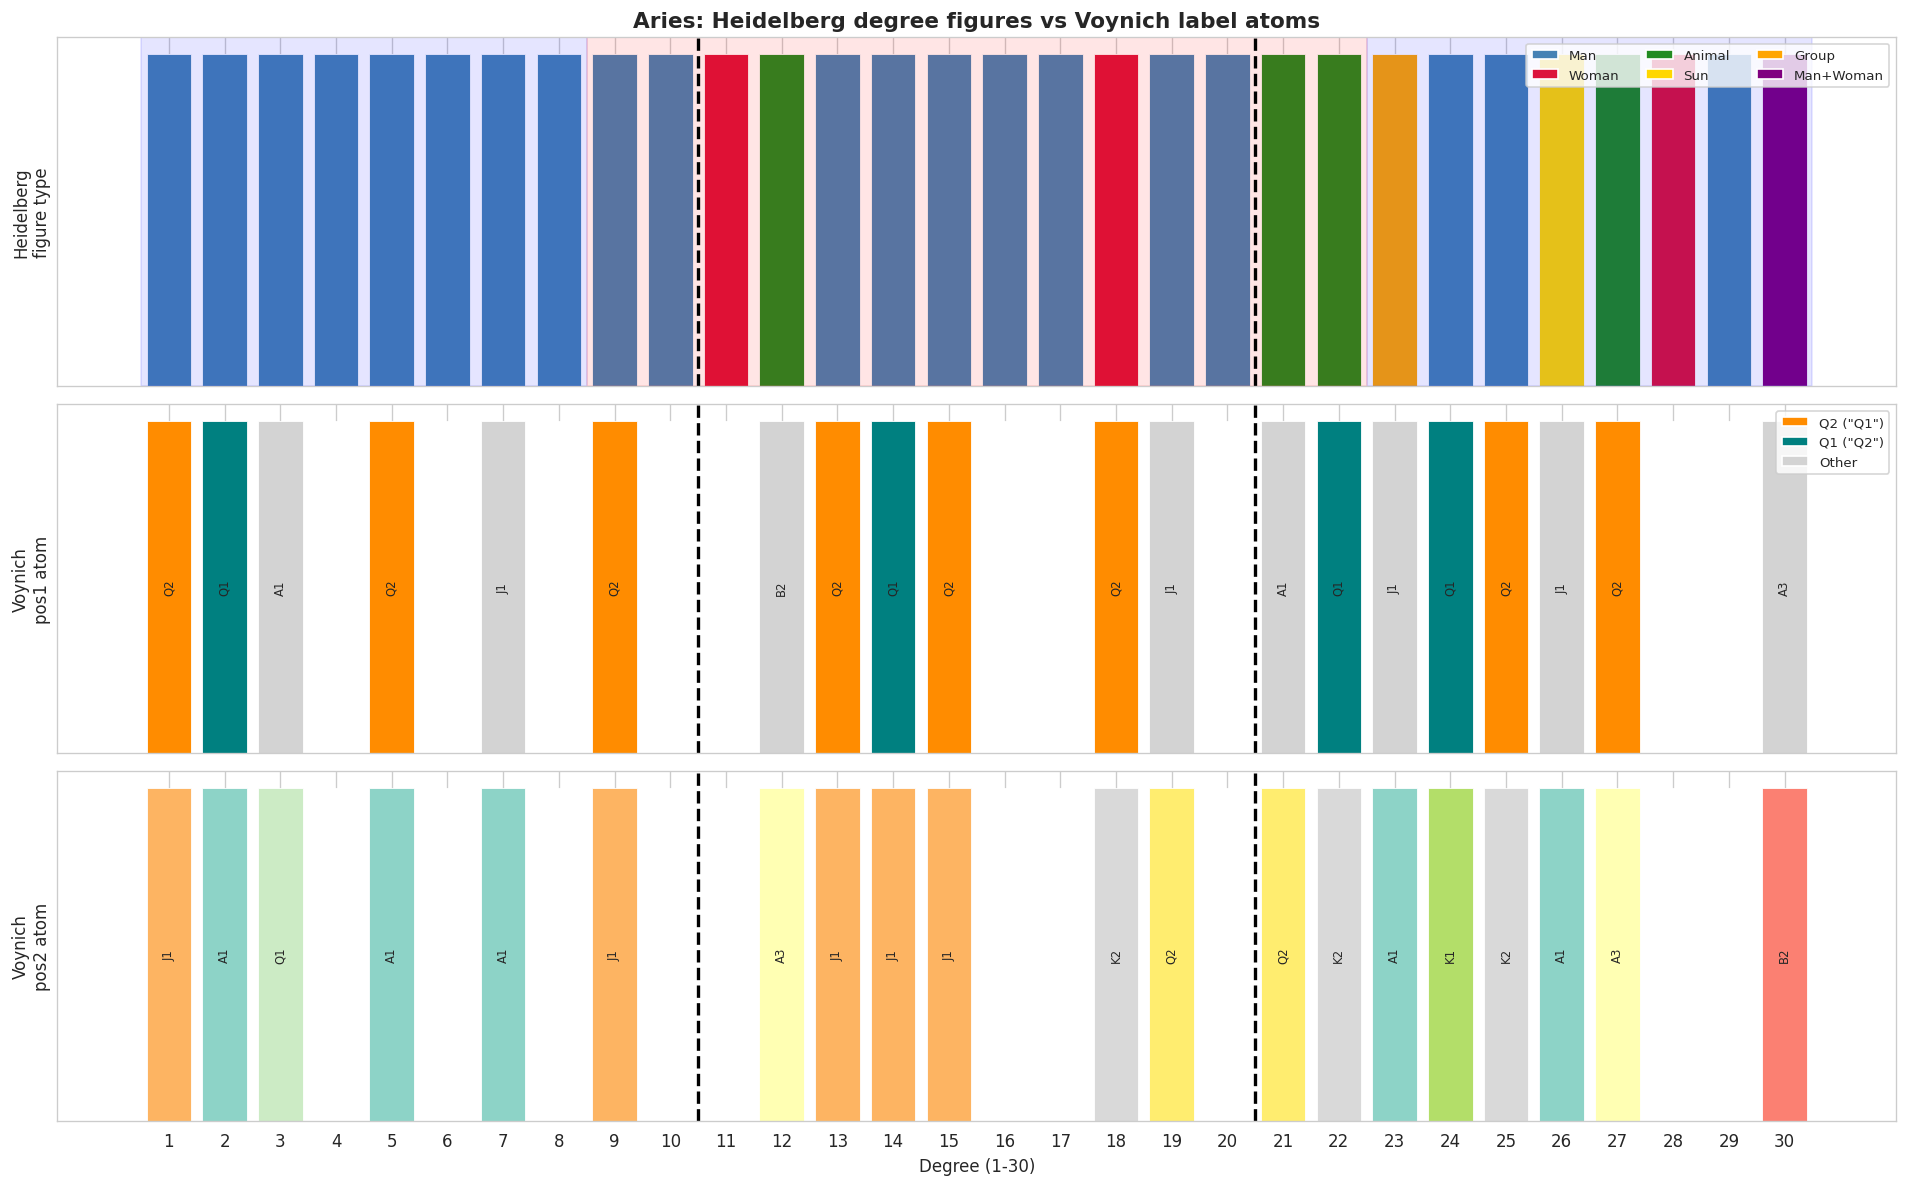

Saved: images/zodiac_aries_heidelberg_voynich.png


In [22]:
# Visualization: Aries degree-by-degree comparison
fig, axes = plt.subplots(3, 1, figsize=(16, 10), sharex=True)

degs = list(range(1, 31))

# Panel 1: Heidelberg figure type
ax = axes[0]
type_colors = {'man': 'steelblue', 'men': 'steelblue', 'woman': 'crimson',
               'animal': 'forestgreen', 'man_woman': 'purple',
               'group': 'orange', 'sun': 'gold', 'ambiguous': 'gray'}
colors_h = [type_colors.get(heid_type.get(d, '?'), 'gray') for d in degs]
ax.bar(degs, [1]*30, color=colors_h, edgecolor='white', linewidth=0.5)
ax.set_ylabel('Heidelberg\nfigure type')
ax.set_yticks([])
# Legend
from matplotlib.patches import Patch
legend_elements = [Patch(facecolor='steelblue', label='Man'),
                   Patch(facecolor='crimson', label='Woman'),
                   Patch(facecolor='forestgreen', label='Animal'),
                   Patch(facecolor='gold', label='Sun'),
                   Patch(facecolor='orange', label='Group'),
                   Patch(facecolor='purple', label='Man+Woman')]
ax.legend(handles=legend_elements, loc='upper right', ncol=3, fontsize=8)
ax.set_title('Aries: Heidelberg degree figures vs Voynich label atoms', fontsize=13, fontweight='bold')
# Decanate lines
for x in [10.5, 20.5]:
    ax.axvline(x, color='black', linewidth=2, linestyle='--')
# Lilly M/F ranges
ax.axvspan(0.5, 8.5, alpha=0.1, color='blue', label='Lilly M')
ax.axvspan(8.5, 22.5, alpha=0.1, color='red', label='Lilly F')
ax.axvspan(22.5, 30.5, alpha=0.1, color='blue')

# Panel 2: Voynich pos1 atom
ax = axes[1]
pos1_vals = []
pos1_colors = []
for d in degs:
    v = next((l for l in aries_labels if l['degree'] + 1 == d), None)
    if v and len(v['atoms']) > 1:
        atom = v['atoms'][1]
        pos1_vals.append(atom)
        if atom == Q1:
            pos1_colors.append('darkorange')
        elif atom == Q2:
            pos1_colors.append('teal')
        else:
            pos1_colors.append('lightgray')
    else:
        pos1_vals.append('-')
        pos1_colors.append('white')

ax.bar(degs, [1]*30, color=pos1_colors, edgecolor='white', linewidth=0.5)
for i, (d, v) in enumerate(zip(degs, pos1_vals)):
    if v != '-':
        ax.text(d, 0.5, v, ha='center', va='center', fontsize=7, rotation=90)
ax.set_ylabel('Voynich\npos1 atom')
ax.set_yticks([])
ax.legend(handles=[Patch(facecolor='darkorange', label=f'{Q1} ("Q1")'),
                   Patch(facecolor='teal', label=f'{Q2} ("Q2")'),
                   Patch(facecolor='lightgray', label='Other')],
         loc='upper right', fontsize=8)
for x in [10.5, 20.5]:
    ax.axvline(x, color='black', linewidth=2, linestyle='--')

# Panel 3: Voynich pos2 atom
ax = axes[2]
pos2_vals = []
pos2_atoms_unique = set()
for d in degs:
    v = next((l for l in aries_labels if l['degree'] + 1 == d), None)
    if v and len(v['atoms']) > 2:
        pos2_vals.append(v['atoms'][2])
        pos2_atoms_unique.add(v['atoms'][2])
    else:
        pos2_vals.append('-')

# Color by atom identity
atom_palette = {a: plt.cm.Set3(i/max(1,len(pos2_atoms_unique)-1)) for i, a in enumerate(sorted(pos2_atoms_unique))}
pos2_colors = [atom_palette.get(v, 'white') for v in pos2_vals]
ax.bar(degs, [1]*30, color=pos2_colors, edgecolor='white', linewidth=0.5)
for i, (d, v) in enumerate(zip(degs, pos2_vals)):
    if v != '-':
        ax.text(d, 0.5, v, ha='center', va='center', fontsize=7, rotation=90)
ax.set_ylabel('Voynich\npos2 atom')
ax.set_yticks([])
ax.set_xlabel('Degree (1-30)')
ax.set_xticks(degs)
for x in [10.5, 20.5]:
    ax.axvline(x, color='black', linewidth=2, linestyle='--')

plt.tight_layout()
plt.savefig('images/zodiac_aries_heidelberg_voynich.png', dpi=150, bbox_inches='tight')
plt.show()
print('Saved: images/zodiac_aries_heidelberg_voynich.png')


In [23]:
# Aries pilot: summary statistics
print('='*70)
print('ARIES PILOT SUMMARY')
print('='*70)
print()

# 1. Heidelberg gender vs Lilly M/F
m_in_m = sum(1 for d in range(1,31) if heid_gender.get(d)=='M' and lilly_mf_aries(d)=='M')
f_in_f = sum(1 for d in range(1,31) if heid_gender.get(d)=='F' and lilly_mf_aries(d)=='F')
total_mf = sum(1 for d in range(1,31) if heid_gender.get(d) in ['M','F'])
print(f'1. Heidelberg figure gender vs Lilly M/F: {m_in_m+f_in_f}/{total_mf} match ({(m_in_m+f_in_f)/total_mf*100:.0f}%)')
print(f'   Men in Lilly-M range: {m_in_m}, Women in Lilly-F range: {f_in_f}')
print(f'   Conclusion: PARTIAL match — Lilly M range is all men,')
print(f'   but Lilly F range is mostly men too (only 2 women in 14 degrees)')
print()

# 2. Non-human figures by decanate
non_human = {d: heid_type[d] for d in range(1,31) if heid_type.get(d) in ['animal','sun']}
print(f'2. Non-human figures: degrees {list(non_human.keys())}')
print(f'   Face 1 (1-10): {sum(1 for d in non_human if d<=10)}')
print(f'   Face 2 (11-20): {sum(1 for d in non_human if 11<=d<=20)}')
print(f'   Face 3 (21-30): {sum(1 for d in non_human if d>=21)}')
print(f'   Non-human figures increase toward Face 3 (21-30)')
print()

# 3. Q1/Q2 vs anything
q1_degs = [l['degree']+1 for l in aries_labels if len(l['atoms'])>1 and l['atoms'][1]==Q1]
q2_degs = [l['degree']+1 for l in aries_labels if len(l['atoms'])>1 and l['atoms'][1]==Q2]
print(f'3. Voynich pos1 in Aries:')
print(f'   {Q1} at degrees: {q1_degs}')
print(f'   {Q2} at degrees: {q2_degs}')
print(f'   {Q1} mean degree: {np.mean(q1_degs):.1f}' if q1_degs else '   Q1: none')
print(f'   {Q2} mean degree: {np.mean(q2_degs):.1f}' if q2_degs else '   Q2: none')
print()

# 4. Overall assessment
print('4. Assessment:')
print('   The Heidelberg and Voynich share the 30-degree structure,')
print('   decanate boundaries, and astrological purpose.')
print('   BUT: Heidelberg encodes UNIQUE descriptions per degree,')
print('   while the Voynich encodes CATEGORICAL sign-level properties.')
print('   The degree-level variation in Heidelberg figures (M/F, human/animal)')
print('   does NOT map onto Voynich atom variation in any obvious way.')
print('   The two manuscripts are FUNCTIONALLY SIMILAR but use different')
print('   encoding granularities — Heidelberg is degree-specific,')
print('   Voynich atoms encode sign-level categories.')


ARIES PILOT SUMMARY

1. Heidelberg figure gender vs Lilly M/F: 13/23 match (57%)
   Men in Lilly-M range: 11, Women in Lilly-F range: 2
   Conclusion: PARTIAL match — Lilly M range is all men,
   but Lilly F range is mostly men too (only 2 women in 14 degrees)

2. Non-human figures: degrees [12, 21, 22, 26, 27]
   Face 1 (1-10): 0
   Face 2 (11-20): 1
   Face 3 (21-30): 4
   Non-human figures increase toward Face 3 (21-30)

3. Voynich pos1 in Aries:
   Q2 at degrees: [1, 5, 9, 13, 15, 18, 25, 27, 32, 37, 40, 41, 45, 53, 55, 59, 62, 65, 66, 69, 70, 72, 80, 82, 83, 88, 90, 91, 92, 97, 100, 102, 103, 105, 107, 108, 109, 111, 115, 116, 126, 127, 128, 129, 130, 132, 133, 138]
   Q1 at degrees: [2, 14, 22, 24, 36, 39, 44, 47, 57, 64, 71, 75, 76, 78, 79, 87, 99, 101, 113, 118, 121, 123, 124, 125, 137, 140]
   Q2 mean degree: 77.1
   Q1 mean degree: 77.5

4. Assessment:
   The Heidelberg and Voynich share the 30-degree structure,
   decanate boundaries, and astrological purpose.
   BUT: Heidel